In [6]:
!pip install -q ultralytics>=8.3.0
!pip install -q git+https://github.com/facebookresearch/sam2.git
!pip install -q transformers>=4.45.0
!pip install -q opencv-python matplotlib pillow

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


#**GPU Check**

In [1]:
import torch
import tensorflow as tf

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU device:      {torch.cuda.get_device_name(0)}")
    print(f"VRAM total:      {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


PyTorch version: 2.11.0+cu130
CUDA Available: True
GPU device:      Tesla T4
VRAM total:      15.6 GB


# **Download Sample Image**

In [2]:
import urllib.request
import os

url = "https://geoawesome.com/wp-content/uploads/2022/03/lidar1.webp"

out_path = "/content/sample_road.jpg"

urllib.request.urlretrieve(url, out_path)
print(f"Saved to {out_path}, size: {os.path.getsize(out_path) // 1024} KB")

Saved to /content/sample_road.jpg, size: 50 KB


# **Visualize the Sample**


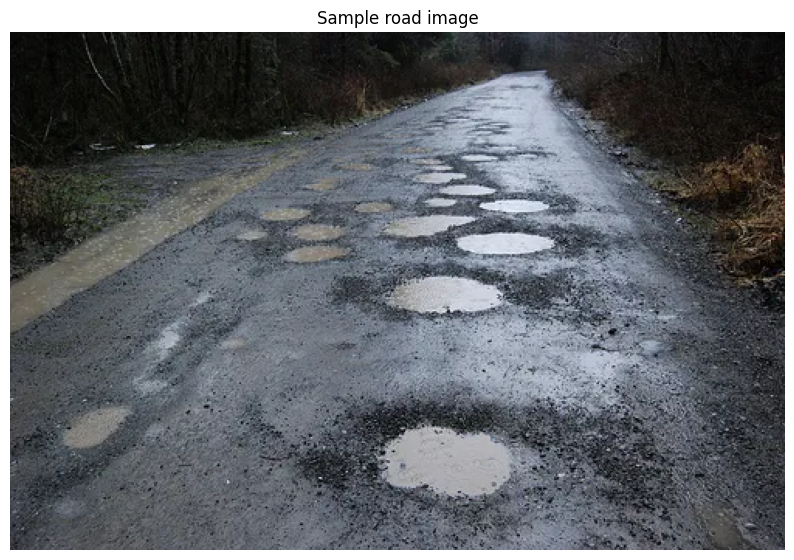

In [4]:
import cv2
import matplotlib.pyplot as plt


image = cv2.imread(out_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis('off')
plt.title('Sample road image')
plt.show()

# **YOLOn Smoke Test**

In [7]:
from ultralytics import YOLO

# load pre-trained YOLO11 nano model
yolo_model= YOLO('yolo26n.pt')

# run inference on sample image
results = yolo_model('/content/sample_road.jpg')

# Result is a list (one per image)
r = results[0]

# print what was detected
print(f"Detected: {len(r.boxes)} objects")

for i, box in enumerate(r.boxes):
    cls_id = int(box.cls[0])
    cls_name = yolo_model.names[cls_id]
    conf = float(box.conf[0])
    xyxy = box.xyxy[0].tolist()
    print(f"  [{i}] {cls_name} (conf={conf:.2f}) at {[round(x) for x in xyxy]}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

image 1/1 /content/sample_road.jpg: 448x640 (no detections), 25.2ms
Speed: 99.9ms preprocess, 25.2ms inference, 9.4ms postprocess per image at shape (1, 3, 448, 640)
Detected: 0 objects


# **Visualize the detections**

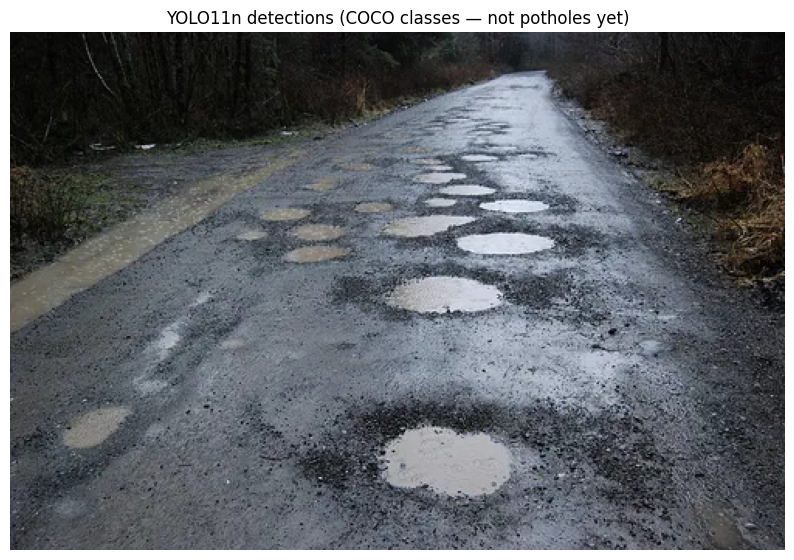

In [8]:
# Built-in Ultralytics plot
annotated = r.plot()  # returns numpy array with bboxes drawn
annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(annotated)
plt.axis('off')
plt.title('YOLO11n detections (COCO classes — not potholes yet)')
plt.show()

#**Download the SAM 2**

In [9]:
# Download SAM 2 tiny checkpoint from Meta's release
import urllib.request
import os

os.makedirs('/content/sam2_checkpoints', exist_ok=True)
url = "https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_tiny.pt"
out = "/content/sam2_checkpoints/sam2_hiera_tiny.pt"

if not os.path.exists(out):
    print("Downloading SAM 2 tiny checkpoint (~40 MB)...")
    urllib.request.urlretrieve(url, out)
print(f"Checkpoint size: {os.path.getsize(out) / 1e6:.1f} MB")

Checkpoint size: 155.9 MB


# **Find the SAM 2 config file**

In [10]:
import sam2
import os

sam2_dir = os.path.dirname(sam2.__file__)
print(f"SAM 2 installed at: {sam2_dir}")

# Look for sam2_hiera_t config
configs_dir = os.path.join(sam2_dir, "configs")
print(f"Configs directory: {configs_dir}")
!ls {configs_dir}
!ls {configs_dir}/sam2.1 2>/dev/null || ls {configs_dir}/sam2 2>/dev/null

SAM 2 installed at: /usr/local/lib/python3.13/dist-packages/sam2
Configs directory: /usr/local/lib/python3.13/dist-packages/sam2/configs
sam2  sam2.1  sam2.1_training
sam2.1_hiera_b+.yaml  sam2.1_hiera_s.yaml
sam2.1_hiera_l.yaml   sam2.1_hiera_t.yaml


# **Load SAM 2 image predictor**

In [12]:
import torch
import os
import urllib.request
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# Ensure we have the correct SAM 2.1 tiny checkpoint to match the SAM 2.1 config
checkpoint_dir = "/content/sam2_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint = os.path.join(checkpoint_dir, "sam2.1_hiera_tiny.pt")

if not os.path.exists(checkpoint):
    url = "https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt"
    print(f"Downloading SAM 2.1 tiny checkpoint...")
    urllib.request.urlretrieve(url, checkpoint)

# Use SAM 2.1 config
config_path = "configs/sam2.1/sam2.1_hiera_t.yaml"

# Build model
device = "cuda" if torch.cuda.is_available() else "cpu"
sam2_model = build_sam2(config_path, checkpoint, device=device)
predictor = SAM2ImagePredictor(sam2_model)
print(f"SAM 2.1 loaded successfully on {device}!")

SAM 2.1 loaded successfully on cuda!


#**Use a YOLO detection as a SAM 2**

In [14]:
import numpy as np

# Take the first YOLO detection (whatever it found — even a car will work for the smoke test)
if len(r.boxes) == 0:
    print("YOLO found nothing. Using image center as fallback prompt.")
    h, w = image.shape[:2]
    input_box = np.array([w//4, h//4, 3*w//4, 3*h//4])
    input_point = np.array([[w//2, h//2]])
    input_label = np.array([1])  # 1 = foreground point
else:
    box = r.boxes[0]
    input_box = np.array(box.xyxy[0].tolist())
    input_point = None
    input_label = None
    print(f"Using YOLO box as prompt: {input_box}")

# Set the image in SAM 2 predictor
predictor.set_image(image)

# Predict mask
masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    box=input_box[None, :],
    multimask_output=False,
)

mask = masks[0]  # binary HxW array
print(f"Mask shape: {mask.shape}, sum (pixels in mask): {mask.sum()}")

YOLO found nothing. Using image center as fallback prompt.
Mask shape: (334, 500), sum (pixels in mask): 47841.0


# **Visualize the Mask**

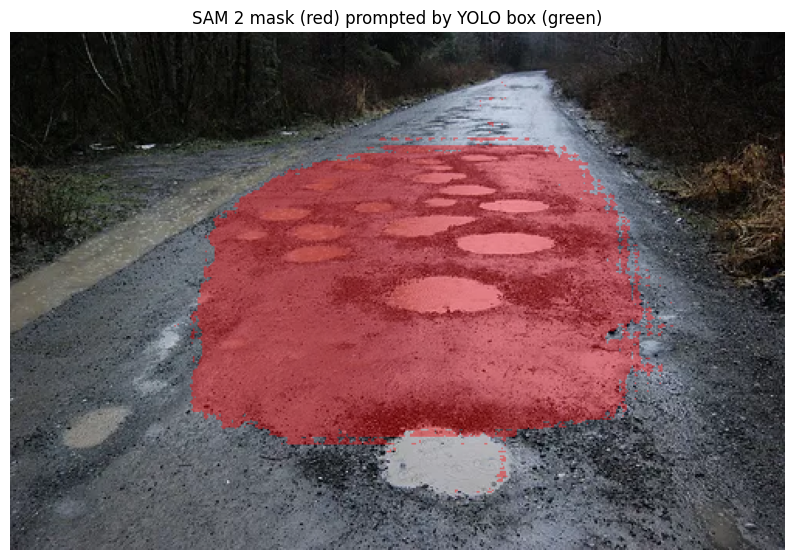

In [17]:
# Overlay mask on the image
overlay = image.copy()

# Convert mask to boolean to fix the indexing IndexError
bool_mask = mask.astype(bool)
overlay[bool_mask] = [255, 0, 0]  # red where mask is True
blended = cv2.addWeighted(image, 0.6, overlay, 0.4, 0)

# Draw the YOLO box too
if len(r.boxes) > 0:
    x1, y1, x2, y2 = [int(v) for v in input_box]
    cv2.rectangle(blended, (x1, y1), (x2, y2), (0, 255, 0), 3)

plt.figure(figsize=(10, 8))
plt.imshow(blended)
plt.axis('off')
plt.title('SAM 2 mask (red) prompted by YOLO box (green)')
plt.show()

#**Depth Anything V2 smoke test**

**Login to Hugging Face**

In [18]:
from huggingface_hub import login
login()  # paste your HF token when prompted

**Load Depth Anything V2 Small**

In [19]:
from transformers import pipeline as hf_pipeline

# Load Depth Anything V2 Small (~27M params, fits in 4GB VRAM)
print("Loading Depth Anything V2 Small...")
depth_pipe = hf_pipeline(
    "depth-estimation",
    model="depth-anything/Depth-Anything-V2-Small-hf"
)
print("Model loaded.")

Loading Depth Anything V2 Small...


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

Model loaded.


**Run depth inference**

In [22]:
# Run depth estimation on the same image
from PIL import Image as PILImage
import numpy as np

pil_img = PILImage.fromarray(image)
depth_result = depth_pipe(pil_img)

# Access the depth map using dictionary lookup instead of attribute notation
depth_map = depth_result['depth']  # PIL Image
depth_array = np.array(depth_map)

print(f"Depth map shape: {depth_array.shape}")
print(f"Depth range: min={depth_array.min()}, max={depth_array.max()}")

Depth map shape: (334, 500)
Depth range: min=0, max=255


**Visualize the Depth Map**

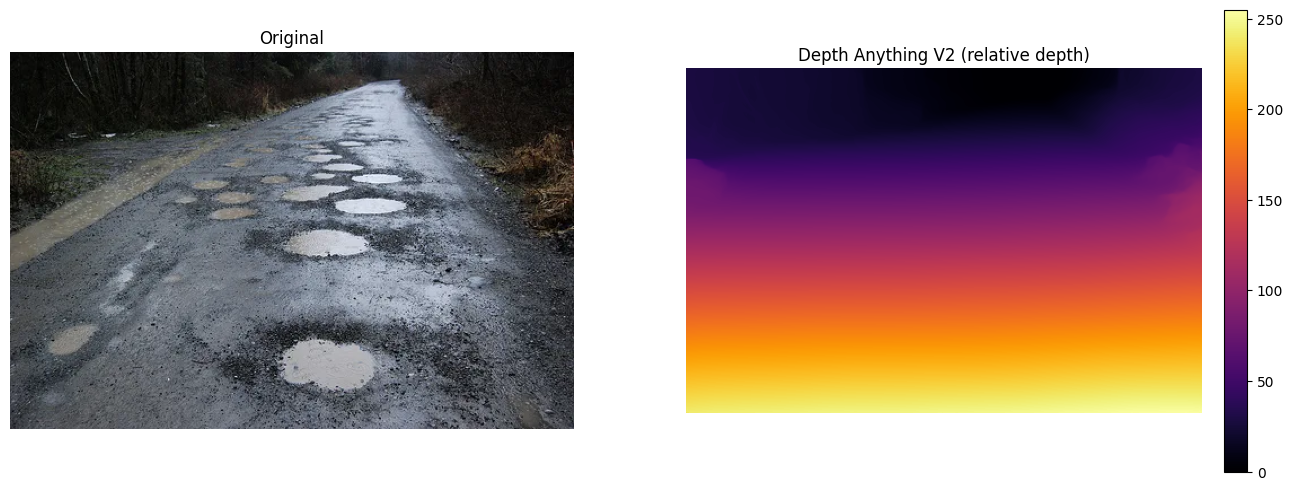

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Corrected 'img' to 'image'
axes[0].imshow(image)
axes[0].set_title('Original')
axes[0].axis('off')

# Use 'inferno' colormap — bright = far, dark = near (or vice versa, depends on model)
depth_vis = axes[1].imshow(depth_array, cmap='inferno')
axes[1].set_title('Depth Anything V2 (relative depth)')
axes[1].axis('off')
plt.colorbar(depth_vis, ax=axes[1], fraction=0.046, pad=0.04)
plt.show()